## Análise Univariada

In [1]:

# importação das bibliotecas

import numpy as np
import pandas as pd
import matplotlib.pyplot  as plt

In [2]:

# Carregando banco de dados

arquivo='/content/pima_diabetes.csv'

tabela=pd.read_csv(arquivo)
tabela.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# Visualizar as colunas do dataset

print(tabela.columns)
print(tabela.shape)

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')
(768, 9)


In [4]:
print(tabela.info)
print(tabela.dtypes)

<bound method DataFrame.info of      Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0              6      148             72             35        0  33.6   
1              1       85             66             29        0  26.6   
2              8      183             64              0        0  23.3   
3              1       89             66             23       94  28.1   
4              0      137             40             35      168  43.1   
..           ...      ...            ...            ...      ...   ...   
763           10      101             76             48      180  32.9   
764            2      122             70             27        0  36.8   
765            5      121             72             23      112  26.2   
766            1      126             60              0        0  30.1   
767            1       93             70             31        0  30.4   

     DiabetesPedigreeFunction  Age  Outcome  
0                       0.627   5

In [5]:

tabela.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [6]:
# Relizar as análises com a variável glicose do dataset

dados_glicose=tabela['Glucose']
dados_glicose

,Glucose
0,148
1,85
2,183
3,89
4,137
...,...
763,101
764,122
765,121
766,126


In [7]:
dados_glicose.isna().sum()

np.int64(0)

In [8]:
# Carregar os dados de glicose e realizar a filtragem para excluir
# campos vazios ou com valores incoerentes

dados_glicose_filtrados = dados_glicose.replace(0, pd.NA).dropna()

In [9]:
# BoxPlot

# Gerar q1,q3,iqr

q1=dados_glicose_filtrados.quantile(0.25)
print('Quartil 1 (percentil 25%): ',q1)
q3=dados_glicose_filtrados.quantile(0.75)
print('Quartil 3 (percentil 75%): ',q3)

iqr=q3-q1
print('IQR: ',iqr)

Quartil 1 (percentil 25%):  99.0
Quartil 3 (percentil 75%):  141.0
IQR:  42.0


In [10]:
lim_inf=q1-1.5*iqr
lim_sup=q3+1.5*iqr

print('Limite inferior: ',lim_inf)
print('Limite superior: ',lim_sup)

Limite inferior:  36.0
Limite superior:  204.0


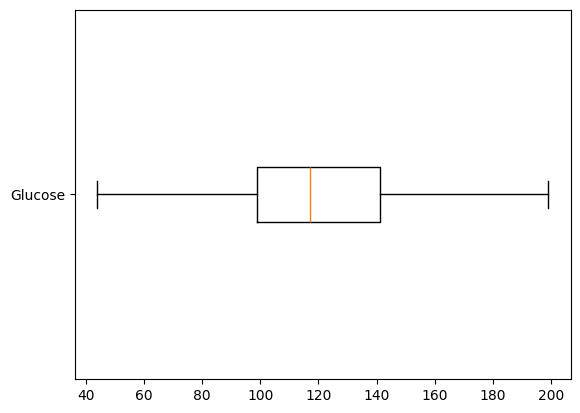

In [11]:
# Gerar boxplot com todos os dados na forma de pontos

plt.boxplot(dados_glicose_filtrados, tick_labels=['Glucose'],vert=False)
plt.show()

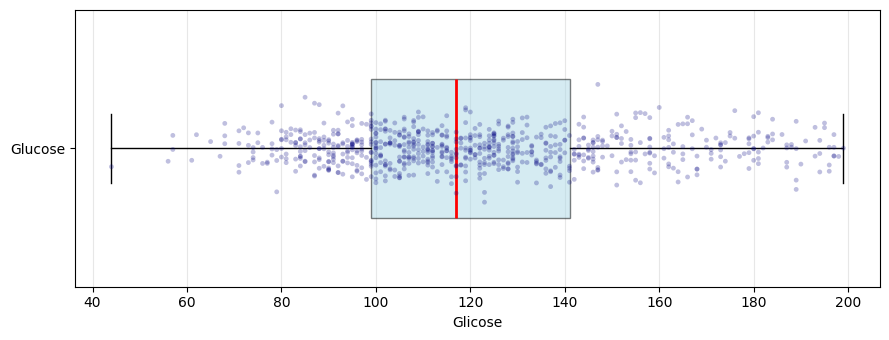

In [12]:
np.random.seed(42)  # jitter sempre igual

plt.figure(figsize=(9, 3.5))

plt.boxplot(dados_glicose_filtrados, tick_labels=['Glucose'], patch_artist=True,
            vert=False, showfliers=False, widths=0.5,
            boxprops={'facecolor': 'lightblue', 'alpha': 0.5},
            medianprops={'color': 'red', 'linewidth': 2})

y = np.random.normal(1, 0.06, size=len(dados_glicose_filtrados))
plt.scatter(dados_glicose_filtrados, y, alpha=0.25, color='navy',
            s=12, edgecolors='none', zorder=3)

plt.xlabel('Glicose')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

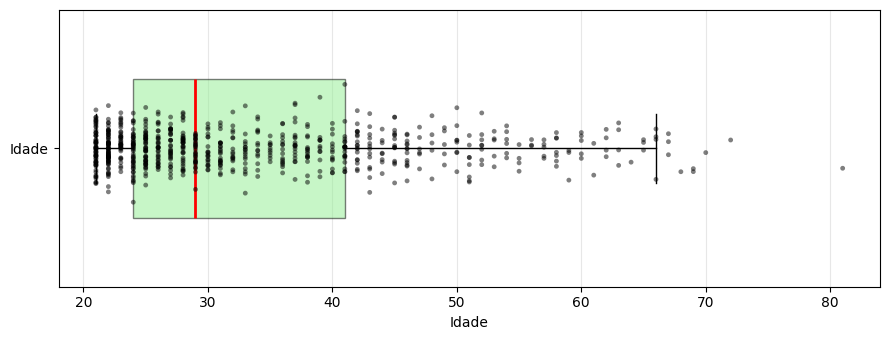

In [13]:
np.random.seed(42)  # jitter sempre igual

plt.figure(figsize=(9, 3.5))

plt.boxplot(tabela['Age'], tick_labels=['Idade'], patch_artist=True,
            vert=False, showfliers=False, widths=0.5,
            boxprops={'facecolor': 'lightgreen', 'alpha': 0.5},
            medianprops={'color': 'red', 'linewidth': 2})

y = np.random.normal(1, 0.06, size=len(tabela))
plt.scatter(tabela['Age'], y, alpha=0.5, color='black',
            s=12, edgecolors='none', zorder=3)

plt.xlabel('Idade')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

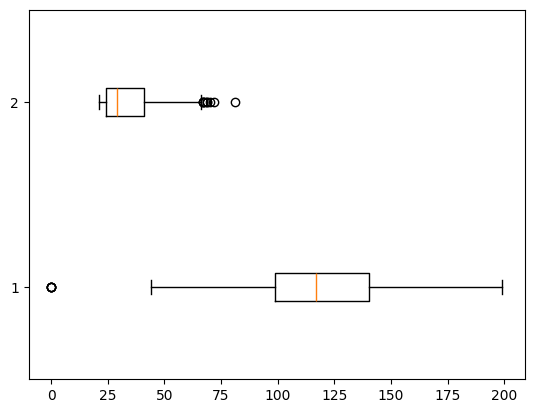

In [14]:
# Exibir mais de um boxplot ao mesmo tempo

plt.boxplot([tabela['Glucose'],tabela['Age']],vert=False)
plt.show()

In [15]:
# Cálculo de skewness
glicose_skew=dados_glicose_filtrados.skew()

print('Skewness de Glicose: ',glicose_skew)


Skewness de Glicose:  0.5309885349396284


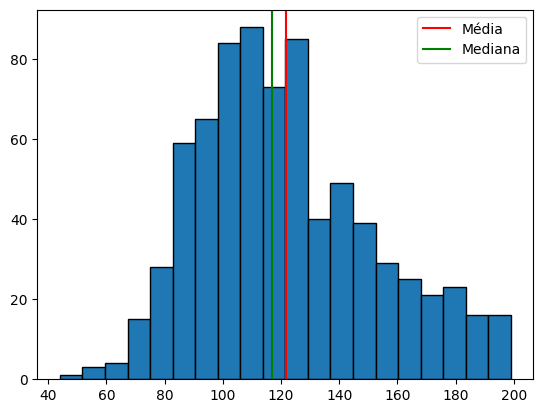

In [16]:
# Histograma

plt.hist(dados_glicose_filtrados,bins=20,edgecolor='black')

plt.axvline(dados_glicose_filtrados.mean(),color='red',label="Média")

plt.axvline(dados_glicose_filtrados.median(),color='green',label='Mediana')

plt.legend()

plt.show()


In [17]:
# Cálculo de skewness


print('Pressão Sanguínea: ',tabela['BloodPressure'].replace(0,pd.NA).dropna().skew())


Pressão Sanguínea:  0.13415273171959258


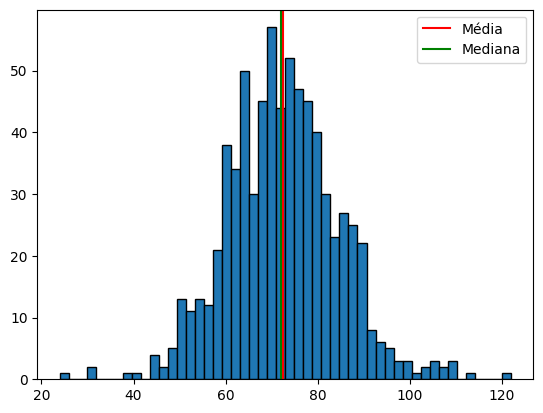

In [18]:
# Histograma

plt.hist(tabela['BloodPressure'].replace(0,pd.NA).dropna(),bins=50,edgecolor='black')

plt.axvline(tabela['BloodPressure'].replace(0,pd.NA).dropna().mean(),color='red',label="Média")

plt.axvline(tabela['BloodPressure'].replace(0,pd.NA).dropna().median(),color='green',label='Mediana')

plt.legend()

plt.show()


In [19]:
# Cálculo da curtose


curtose=dados_glicose_filtrados.kurt()
print(f'Curtose de glicemia: {curtose:.2f}')

Curtose de glicemia: -0.28


In [20]:
# Cálculo de z-score de glicose

z=(dados_glicose_filtrados-dados_glicose_filtrados.mean())/dados_glicose_filtrados.std()

print(z.head())

0    0.861722
1   -1.201441
2    2.007924
3   -1.070446
4    0.501487
Name: Glucose, dtype: object


# Análise multivariada

In [21]:
# Geração de PCA com glicose e BMI(IMC)

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [22]:
# Carregamento dos dados do arquivo de dados

df=pd.read_csv('/content/pima_diabetes.csv')
novo_df=df[['Glucose','BMI','Outcome']].copy()
novo_df[['Glucose','BMI']]=novo_df[['Glucose','BMI']].replace(0,pd.NA)
novo_df=novo_df.dropna()

novo_df.head()


,Glucose,BMI,Outcome
0,148,33.6,1
1,85,26.6,0
2,183,23.3,1
3,89,28.1,0
4,137,43.1,1


In [27]:
X=StandardScaler().fit_transform(novo_df[['Glucose','BMI']])
y=novo_df['Outcome'].to_numpy()

In [30]:
# Cáculo do PCA

pca=PCA(n_components=2)
Xp=pca.fit_transform(X)
v=pca.explained_variance_ratio_*100

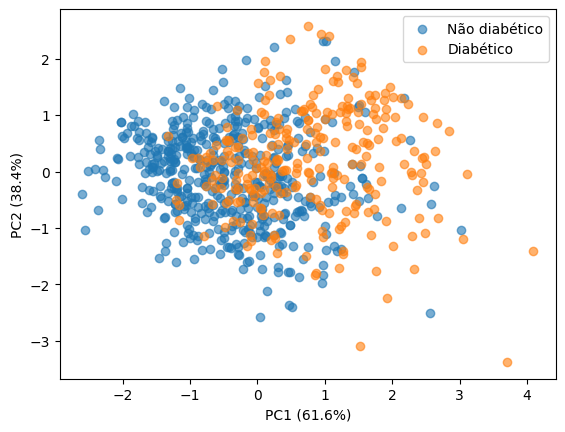

In [32]:
# Geração do gráfico


plt.scatter(Xp[y==0, 0], Xp[y==0, 1], label="Não diabético", alpha=0.6)
plt.scatter(Xp[y==1, 0], Xp[y==1, 1], label="Diabético", alpha=0.6)
plt.xlabel(f'PC1 ({v[0]:.1f}%)')
plt.ylabel(f'PC2 ({v[1]:.1f}%)')
plt.legend()
plt.show()
